# CA-11

From `FINDINGS.md`:

> Scott Wiener 157,394 (53.6 percent), Connie Chan 136,435 (46.4 percent). Both are Democrats, so the map uses a purple-orange scale. The district is 453 of 514 precincts. The other 61 are in CA-15 and are hatched gray on the map. They form the city’s southern band. 56 of them are in the Excelsior, the Outer Mission, Oceanview–Merced–Ingleside, Portola, and Visitacion Valley, and the other five are around McLaren Park and in Bayview. The Lake Merced corner in the southwest is in CA-11.
>
> Precinct shares inside the district, among those with at least 50 ballots, run from 35.2 percent to 46.8 percent to 59.0 percent. Chan leads in the Sunset, the Outer Richmond, the Mission, Bayview, and Chinatown. Wiener leads in the Inner Richmond, the Castro, Noe Valley, and most of the north side, from the Marina to Pacific Heights. Counting CA-11 precincts only, Chan’s share is 58.9 percent in supervisor District 4, 53.2 percent in District 9, and 51.0 percent in District 1. It is 37.2 percent in District 8 and 37.5 percent in District 2. Supervisor District 11 contributes only 1,745 votes to this race, because most of that supervisor district sits in CA-15. Those votes are 58.2 percent Chan.
>
> Chan’s share is lower where the non-Hispanic white share is higher (r = −0.70) and where the bachelor’s-degree share is higher (r = −0.63). It rises with the non-Hispanic Asian share (r = 0.55) and with the foreign-born share (r = 0.48). Those four move together across the west side of the district.

Every number below is computed from the files in `source/`. Run the setup cell first, then the rest in order (Runtime → Run all). The last cell lists each number the memo section quotes next to the value computed here, and stops with an error if any differ.

In [1]:
# Run this cell first. It finds the sf-2026-drive folder (on Google Drive in Colab, or on
# this computer) and loads the shared code in notebooks/sf2026.py.
import subprocess
import sys
from pathlib import Path

try:
    import geopandas  # noqa: F401
except ImportError:
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "geopandas"], check=True)

FOLDER_NAME = "sf-2026-drive"


def is_root(path: Path) -> bool:
    return (path / "source" / "precinct_results.csv").exists() and (path / "notebooks" / "sf2026.py").exists()


def find_root() -> Path:
    here = Path.cwd().resolve()
    for candidate in [here, *here.parents]:
        if is_root(candidate):
            return candidate
    try:
        from google.colab import drive
    except ImportError:
        raise FileNotFoundError("Open this notebook from inside the sf-2026-drive folder.")
    drive.mount("/content/drive")
    bases = [Path("/content/drive/MyDrive"), Path("/content/drive/Shareddrives")]
    for base in bases:
        if is_root(base / FOLDER_NAME):
            return base / FOLDER_NAME
    for base in bases:
        if base.exists():
            for helper in base.rglob("sf2026.py"):
                if is_root(helper.parent.parent):
                    return helper.parent.parent
    raise FileNotFoundError(
        f"Could not find the {FOLDER_NAME} folder on Drive. If you renamed it, set FOLDER_NAME above."
    )


ROOT = find_root()
sys.path.insert(0, str(ROOT / "notebooks"))
import pandas as pd
import sf2026 as sf

pd.set_option("display.float_format", lambda value: f"{value:,.2f}")
data = sf.load(ROOT)
check = sf.MemoCheck()
print(f"Using the {ROOT.name} folder: {len(data)} precincts")

Using the sf-2026-drive folder: 514 precincts


## Citywide result and the district line

In [2]:
in_ca11 = data["Congressional"] == 11
city = sf.citywide(data, "wiener", "chan")
check.number("Wiener votes", 157394, city["wiener"], 0)
check.number("Wiener share, percent", 53.6, city["share_pct"])
check.number("Chan votes", 136435, city["chan"], 0)
check.number("Chan share, percent", 46.4, 100 - city["share_pct"])
check.number("Precincts in CA-11", 453, in_ca11.sum(), 0)
check.number("Precincts in CA-15", 61, (data["Congressional"] == 15).sum(), 0)
city

{'wiener': 157394,
 'chan': 136435,
 'share_pct': 53.56653019273114,
 'margin': 20959}

In [3]:
ca15 = data[data["Congressional"] == 15]["Neighborhood"].value_counts()
band = ["EXCELSIOR", "OUTER MISSION", "OCEANVIEW/MERCED/INGLESIDE", "PORTOLA", "VISITACION VALLEY"]
check.number("CA-15 precincts in the five southern neighborhoods", 56, ca15.reindex(band).fillna(0).sum(), 0)
check.fact("The other CA-15 precincts", "around McLaren Park and in Bayview",
           dict(ca15.drop(band, errors="ignore")),
           set(ca15.drop(band, errors="ignore").index) <= {"MCLAREN PARK", "BAYVIEW HUNTERS POINT"})
lake = data[data["Neighborhood"] == "LAKESHORE"]
check.fact("Lake Merced corner (Lakeshore precincts) is in CA-11", "all in CA-11",
           f"{(lake['Congressional'] == 11).sum()} of {len(lake)}", bool((lake["Congressional"] == 11).all()))
ca15.to_frame("CA-15 precincts")

,CA-15 precincts
Neighborhood,
EXCELSIOR,17
OUTER MISSION,12
OCEANVIEW/MERCED/INGLESIDE,11
PORTOLA,9
VISITACION VALLEY,7
MCLAREN PARK,4
BAYVIEW HUNTERS POINT,1


## Precinct and supervisor-district geography, CA-11 precincts only

In [4]:
share, votes = sf.two_way(data, "chan", "wiener")
enough = (data["ballots"] >= sf.MIN_BALLOTS) & in_ca11
ca11 = data[in_ca11]
districts = sf.by_district(ca11, "chan", "wiener")
neighborhoods = sf.by_neighborhood(ca11, "chan", "wiener").sort_values(ascending=False)
display(neighborhoods.round(1).to_frame("Chan share by neighborhood, percent"))
districts.round(1).to_frame("Chan share by supervisor district, percent")

,"Chan share by neighborhood, percent"
Neighborhood,
CHINATOWN,60.80
LINCOLN PARK,59.00
SUNSET/PARKSIDE,58.90
OCEANVIEW/MERCED/INGLESIDE,58.20
LAKESHORE,55.30
BAYVIEW HUNTERS POINT,54.80
MISSION,53.60
OUTER RICHMOND,53.10
TREASURE ISLAND,51.60


,"Chan share by supervisor district, percent"
Supervisorial,
1,51.00
2,37.50
3,47.30
4,58.90
5,45.90
6,41.60
7,47.20
8,37.20
9,53.20


In [5]:
for name, memo, value in zip(["10th", "50th", "90th"], [35.2, 46.8, 59.0], sf.percentile_range(share, enough)):
    check.number(f"Precinct share, {name} percentile", memo, value)
chan_leads = ["SUNSET/PARKSIDE", "OUTER RICHMOND", "MISSION", "BAYVIEW HUNTERS POINT", "CHINATOWN"]
wiener_leads = ["INNER RICHMOND", "CASTRO/UPPER MARKET", "NOE VALLEY", "MARINA", "PACIFIC HEIGHTS"]
check.fact("Chan leads", ", ".join(chan_leads), neighborhoods[chan_leads].round(1).tolist(), bool((neighborhoods[chan_leads] > 50).all()))
check.fact("Wiener leads", ", ".join(wiener_leads), neighborhoods[wiener_leads].round(1).tolist(), bool((neighborhoods[wiener_leads] < 50).all()))
check.number("Chan share, District 4", 58.9, districts[4])
check.number("Chan share, District 9", 53.2, districts[9])
check.number("Chan share, District 1", 51.0, districts[1])
check.number("Chan share, District 8", 37.2, districts[8])
check.number("Chan share, District 2", 37.5, districts[2])
check.number("Chan share, District 11", 58.2, districts[11])
sd11 = ca11[ca11["Supervisorial"] == 11]
check.number("Supervisor District 11 votes in this race", 1745, sd11["chan"].sum() + sd11["wiener"].sum(), 0)

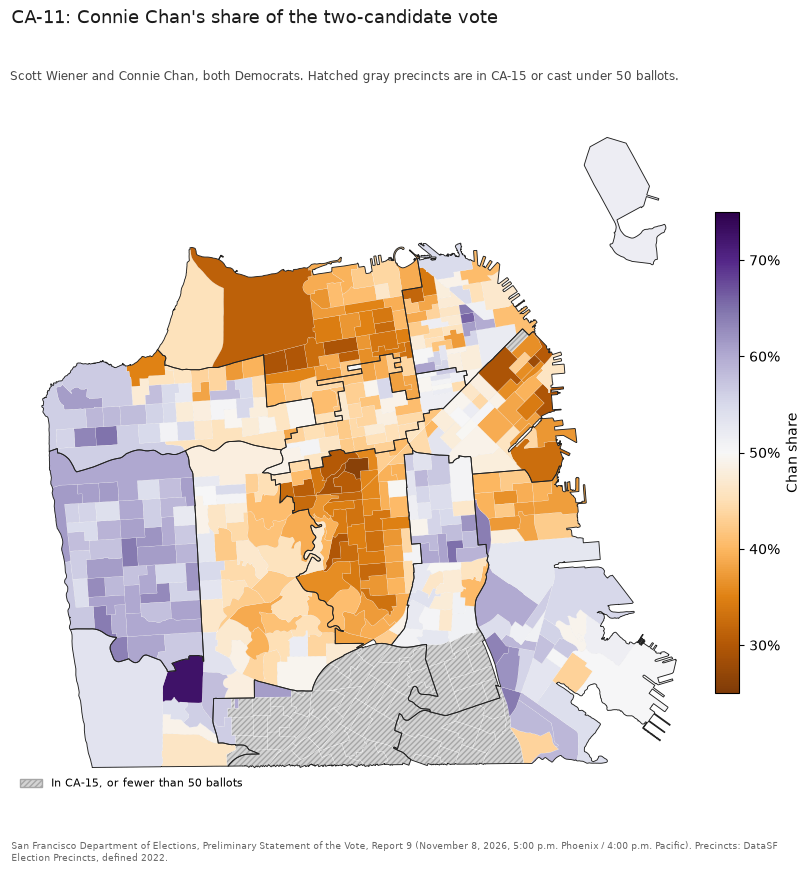

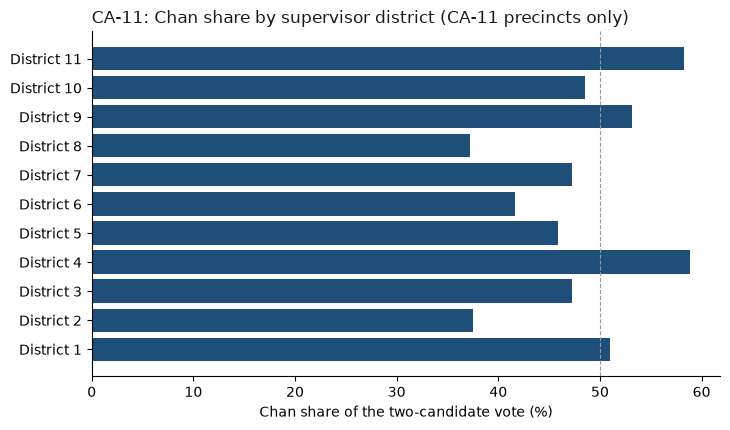

In [6]:
sf.rate_map(data, share, votes, "CA-11: Connie Chan's share of the two-candidate vote",
            "Scott Wiener and Connie Chan, both Democrats. Hatched gray precincts are in CA-15 or cast under 50 ballots.",
            "Chan share", cmap="PuOr", keep=in_ca11, missing_label="In CA-15, or fewer than 50 ballots")
sf.district_bars(ca11.assign(weight=votes[in_ca11], share=share[in_ca11]), "share", None,
                 "CA-11: Chan share by supervisor district (CA-11 precincts only)",
                 "Chan share of the two-candidate vote (%)");

## Census comparison, CA-11 precincts only

,r
Non-Hispanic Asian,0.55
Non-Hispanic white,-0.70
Hispanic,0.29
Bachelor's degree or higher,-0.63
Renters,-0.14
"Households at $150,000+",-0.45
Foreign born,0.48


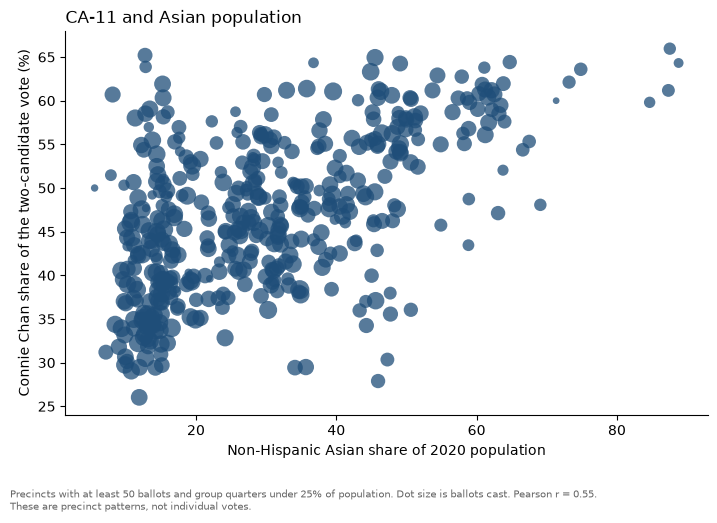

In [7]:
keep = sf.census_frame(data) & in_ca11
r = sf.census_correlations(data, share, keep)
display(r.to_frame())
check.number("Correlation with Non-Hispanic white", -0.7, r["Non-Hispanic white"], 2)
check.number("Correlation with Bachelor's degree or higher", -0.63, r["Bachelor's degree or higher"], 2)
check.number("Correlation with Non-Hispanic Asian", 0.55, r["Non-Hispanic Asian"], 2)
check.number("Correlation with Foreign born", 0.48, r["Foreign born"], 2)
sf.census_scatter(data[keep].assign(share=share[keep]), "share", "nh_asian_share", None,
                  "CA-11 and Asian population", "Non-Hispanic Asian share of 2020 population",
                  "Connie Chan share of the two-candidate vote (%)");

## Numbers the memo quotes

In [8]:
check.report();

,claim,memo,computed,matches
0,Wiener votes,"157,394","157,394",yes
1,"Wiener share, percent",53.6,53.6,yes
2,Chan votes,"136,435","136,435",yes
3,"Chan share, percent",46.4,46.4,yes
4,Precincts in CA-11,453,453,yes
5,Precincts in CA-15,61,61,yes
6,CA-15 precincts in the five southern neighborhoods,56,56,yes
7,The other CA-15 precincts,around McLaren Park and in Bayview,"{'MCLAREN PARK': np.int64(4), 'BAYVIEW HUNTERS POINT': np.int64(1)}",yes
8,Lake Merced corner (Lakeshore precincts) is in CA-11,all in CA-11,6 of 6,yes
9,"Precinct share, 10th percentile",35.2,35.2,yes


All 25 numbers checked match the memo.
